In [1]:
import sys
print(sys.version)
print(sys.executable)

3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:11:29) [Clang 20.1.8 ]
/opt/anaconda3/bin/python


In [2]:
!pip install requests pymupdf

### Downloading the BEIR dataset
downloadin ready made dataset to test search quality

In [3]:
import requests, zipfile, os

url="https://public.ukp.informatik.tu-darmstadt.de/thakur/BEIR/datasets/scifact.zip"
os.makedirs("../data", exist_ok=True)

r = requests.get(url)
with open("../data/scifact.zip", "wb") as f:
    f.write(r.content)

with zipfile.ZipFile("../data/scifact.zip") as z:
    z.extractall("../data")

print(os.listdir("../data/scifact"))

['qrels', 'corpus.jsonl', 'queries.jsonl']


In [4]:
import json

with open("../data/scifact/corpus.jsonl") as f:
    docs=[json.loads(line) for line in f]
print(len(docs))
print(docs[0])

5183
{'_id': '4983', 'title': 'Microstructural development of human newborn cerebral white matter assessed in vivo by diffusion tensor magnetic resonance imaging.', 'text': 'Alterations of the architecture of cerebral white matter in the developing human brain can affect cortical development and result in functional disabilities. A line scan diffusion-weighted magnetic resonance imaging (MRI) sequence with diffusion tensor analysis was applied to measure the apparent diffusion coefficient, to calculate relative anisotropy, and to delineate three-dimensional fiber architecture in cerebral white matter in preterm (n = 17) and full-term infants (n = 7). To assess effects of prematurity on cerebral white matter development, early gestation preterm infants (n = 10) were studied a second time at term. In the central white matter the mean apparent diffusion coefficient at 28 wk was high, 1.8 microm2/ms, and decreased toward term to 1.2 microm2/ms. In the posterior limb of the internal capsule

### Collecting 100+ PDFFs
downloading 130 real pdfs from arxiv

In [5]:
import time
import xml.etree.ElementTree as et

pdf_dir = "../PDFs"
os.makedirs(pdf_dir, exist_ok=True)

ATOM = "{http://www.w3.org/2005/Atom}"
ARXIV = "{http://arxiv.org/schemas/atom}"
HEADERS = {"User-Agent": "internship-rag-project/1.0"}

def fetch_papers(query, max_results):
    r = requests.get(
        "https://export.arxiv.org/api/query",
        params={"search_query": query, "start": 0,
                "max_results": max_results, "sortBy": "relevance"},
        headers=HEADERS, timeout=60,
    )
    r.raise_for_status()
    root = et.fromstring(r.text)

    papers=[]
    for e in root.findall(ATOM + "entry"):
        arxiv_id = e.find(ATOM + "id").text.split("/abs/")[-1]
        papers.append({
            "id": arxiv_id,
            "title": " ".join(e.find(ATOM + "title").text.split()),
            "author": [a.find(ATOM + "name").text for a in e.findall(ATOM + "author")],
            "published": e.find(ATOM + "published").text[:10],
            "category": e.find(ARXIV + "primary_category").get("term"),
            "filename": arxiv_id.replace("/","_") + ".pdf",
        })
    return papers
if os.path.exists("../data/arxiv_metadata.json"):
    with open("../data/arxiv_metadata.json") as f:
        papers = json.load(f)
    print("Loaded existing paper list:", len(papers))
else:
    papers = fetch_papers('all:"retrieval augmented generation"', 130)
    print("Papers found:", len(papers))
    print(papers[0])

Loaded existing paper list: 130


In [6]:
import os

if len(os.listdir("../PDFs")) >= 100:
    print("PDFs already downloaded, skipping.")
else:
    downloaded = []
    for i, p in enumerate(papers):
        path = os.path.join(PDF_DIR, p["filename"])
        if os.path.exists(path):
            downloaded.append(p)
            continue
        try:
            r = requests.get(f"https://arxiv.org/pdf/{p['id']}", headers=HEADERS, timeout=60)
            if r.status_code == 200:
                with open(path, "wb") as f:
                    f.write(r.content)
                downloaded.append(p)
                print(f"[{i+1}/{len(papers)}] OK  {p['title'][:60]}")
            else:
                print(f"[{i+1}/{len(papers)}] FAILED (status {r.status_code})")
        except Exception as ex:
            print(f"[{i+1}/{len(papers)}] ERROR {ex}")
        time.sleep(3)

    os.makedirs("../data", exist_ok=True)
    with open("../data/arxiv_metadata.json", "w") as f:
        json.dump(downloaded, f, indent=2)
    print("Done. PDFs downloaded:", len(downloaded))

PDFs already downloaded, skipping.


### Extracting text from PDFs
opening each pdf and pulling out raw text

In [7]:
import os, json, pymupdf as fitz #pymupdf

pdf_files = [f for f in os.listdir(pdf_dir) if f.endswith(".pdf")]
print(len(pdf_files))

130


In [8]:
extracted_docs = []

for i, filename in enumerate(pdf_files):
    path = os.path.join(pdf_dir, filename)
    try:
        doc = fitz.open(path)
        pages = []
        for page_num, page in enumerate(doc):
            text = page.get_text()
            pages.append({"page_num": page_num + 1, "text": text})
        doc.close()

        full_text = "\n".join(p["text"] for p in pages)
        extracted_docs.append({
            "filename": filename,
            "num_pages": len(pages),
            "pages": pages,
            "full_text": full_text,
        })

    except Exception as e:
        print(f"FAILED: {filename} -> {e}")
print(len(extracted_docs))

130


In [9]:
print(extracted_docs[0]["filename"])
print(extracted_docs[0]["num_pages"], "pages")
print(extracted_docs[0]["pages"][0]["text"][:500])

2501.05475v1.pdf
12 pages
Retrieval-Augmented Generation by Evidence Retroactivity in LLMs
Liang Xiao1*, Wen Dai2, Shuai Chen2, Bin Qin2, Chongyang Shi1†, Haopeng Jing1, Tianyu Guo1
1Beijing Institute of Technology, 2Xiaomi Corporation
{patrickxiao, cy shi, jinghp, guotianyu}@bit.edu.cn, {daiwen, chenshuai3, qinbin}@xiaomi.com
Abstract
Retrieval-augmented generation has gained significant atten-
tion due to its ability to integrate relevant external knowl-
edge, enhancing the accuracy and reliability of the LLMs’
respons


In [10]:
with open("../processed/extracted_docs.json","w") as f:
    json.dump(extracted_docs, f)
    

### OCR for scanned documents
OCR: for pdfs which are just photo of a page not real text.

checking to see any pages with little to no text

In [11]:
low_text_pages=[]
for doc in extracted_docs:
    for page in doc["pages"]:
        if len(page["text"].strip()) <20:
            low_text_pages.append((doc["filename"], page["page_num"]))

print(len(low_text_pages))
print(low_text_pages[:10])

1
[('2505.04680v1.pdf', 45)]


All 130 PDFs collected for this project are "born-digital" arXiv papers meaning they were generated directly as text not scanned from paper. A check in Step 4 confirmed this: out of thousands of pages, only 1 page had close to no extractable text, and that is almost certainly a blank or image-only page, not a scanned document.

Because of this, OCR is not actually needed for this project's real dataset. It is included here to demonstrate the skill, since real-world document collections often do require it.|

In [12]:
!pip install pytesseract pdf2image

In [13]:
from pdf2image import convert_from_path

sample_pdf = "../PDFs/2501.05475v1.pdf"
ocr_dir = "../processed/ocr_test"
os.makedirs(ocr_dir, exist_ok=True)

#converting 1 page into image
pages = convert_from_path(sample_pdf, dpi=200, first_page=1, last_page=1)
image_path = os.path.join(ocr_dir, "scanned_page1.png")
pages[0].save(image_path, "PNG")

print(image_path)

../processed/ocr_test/scanned_page1.png


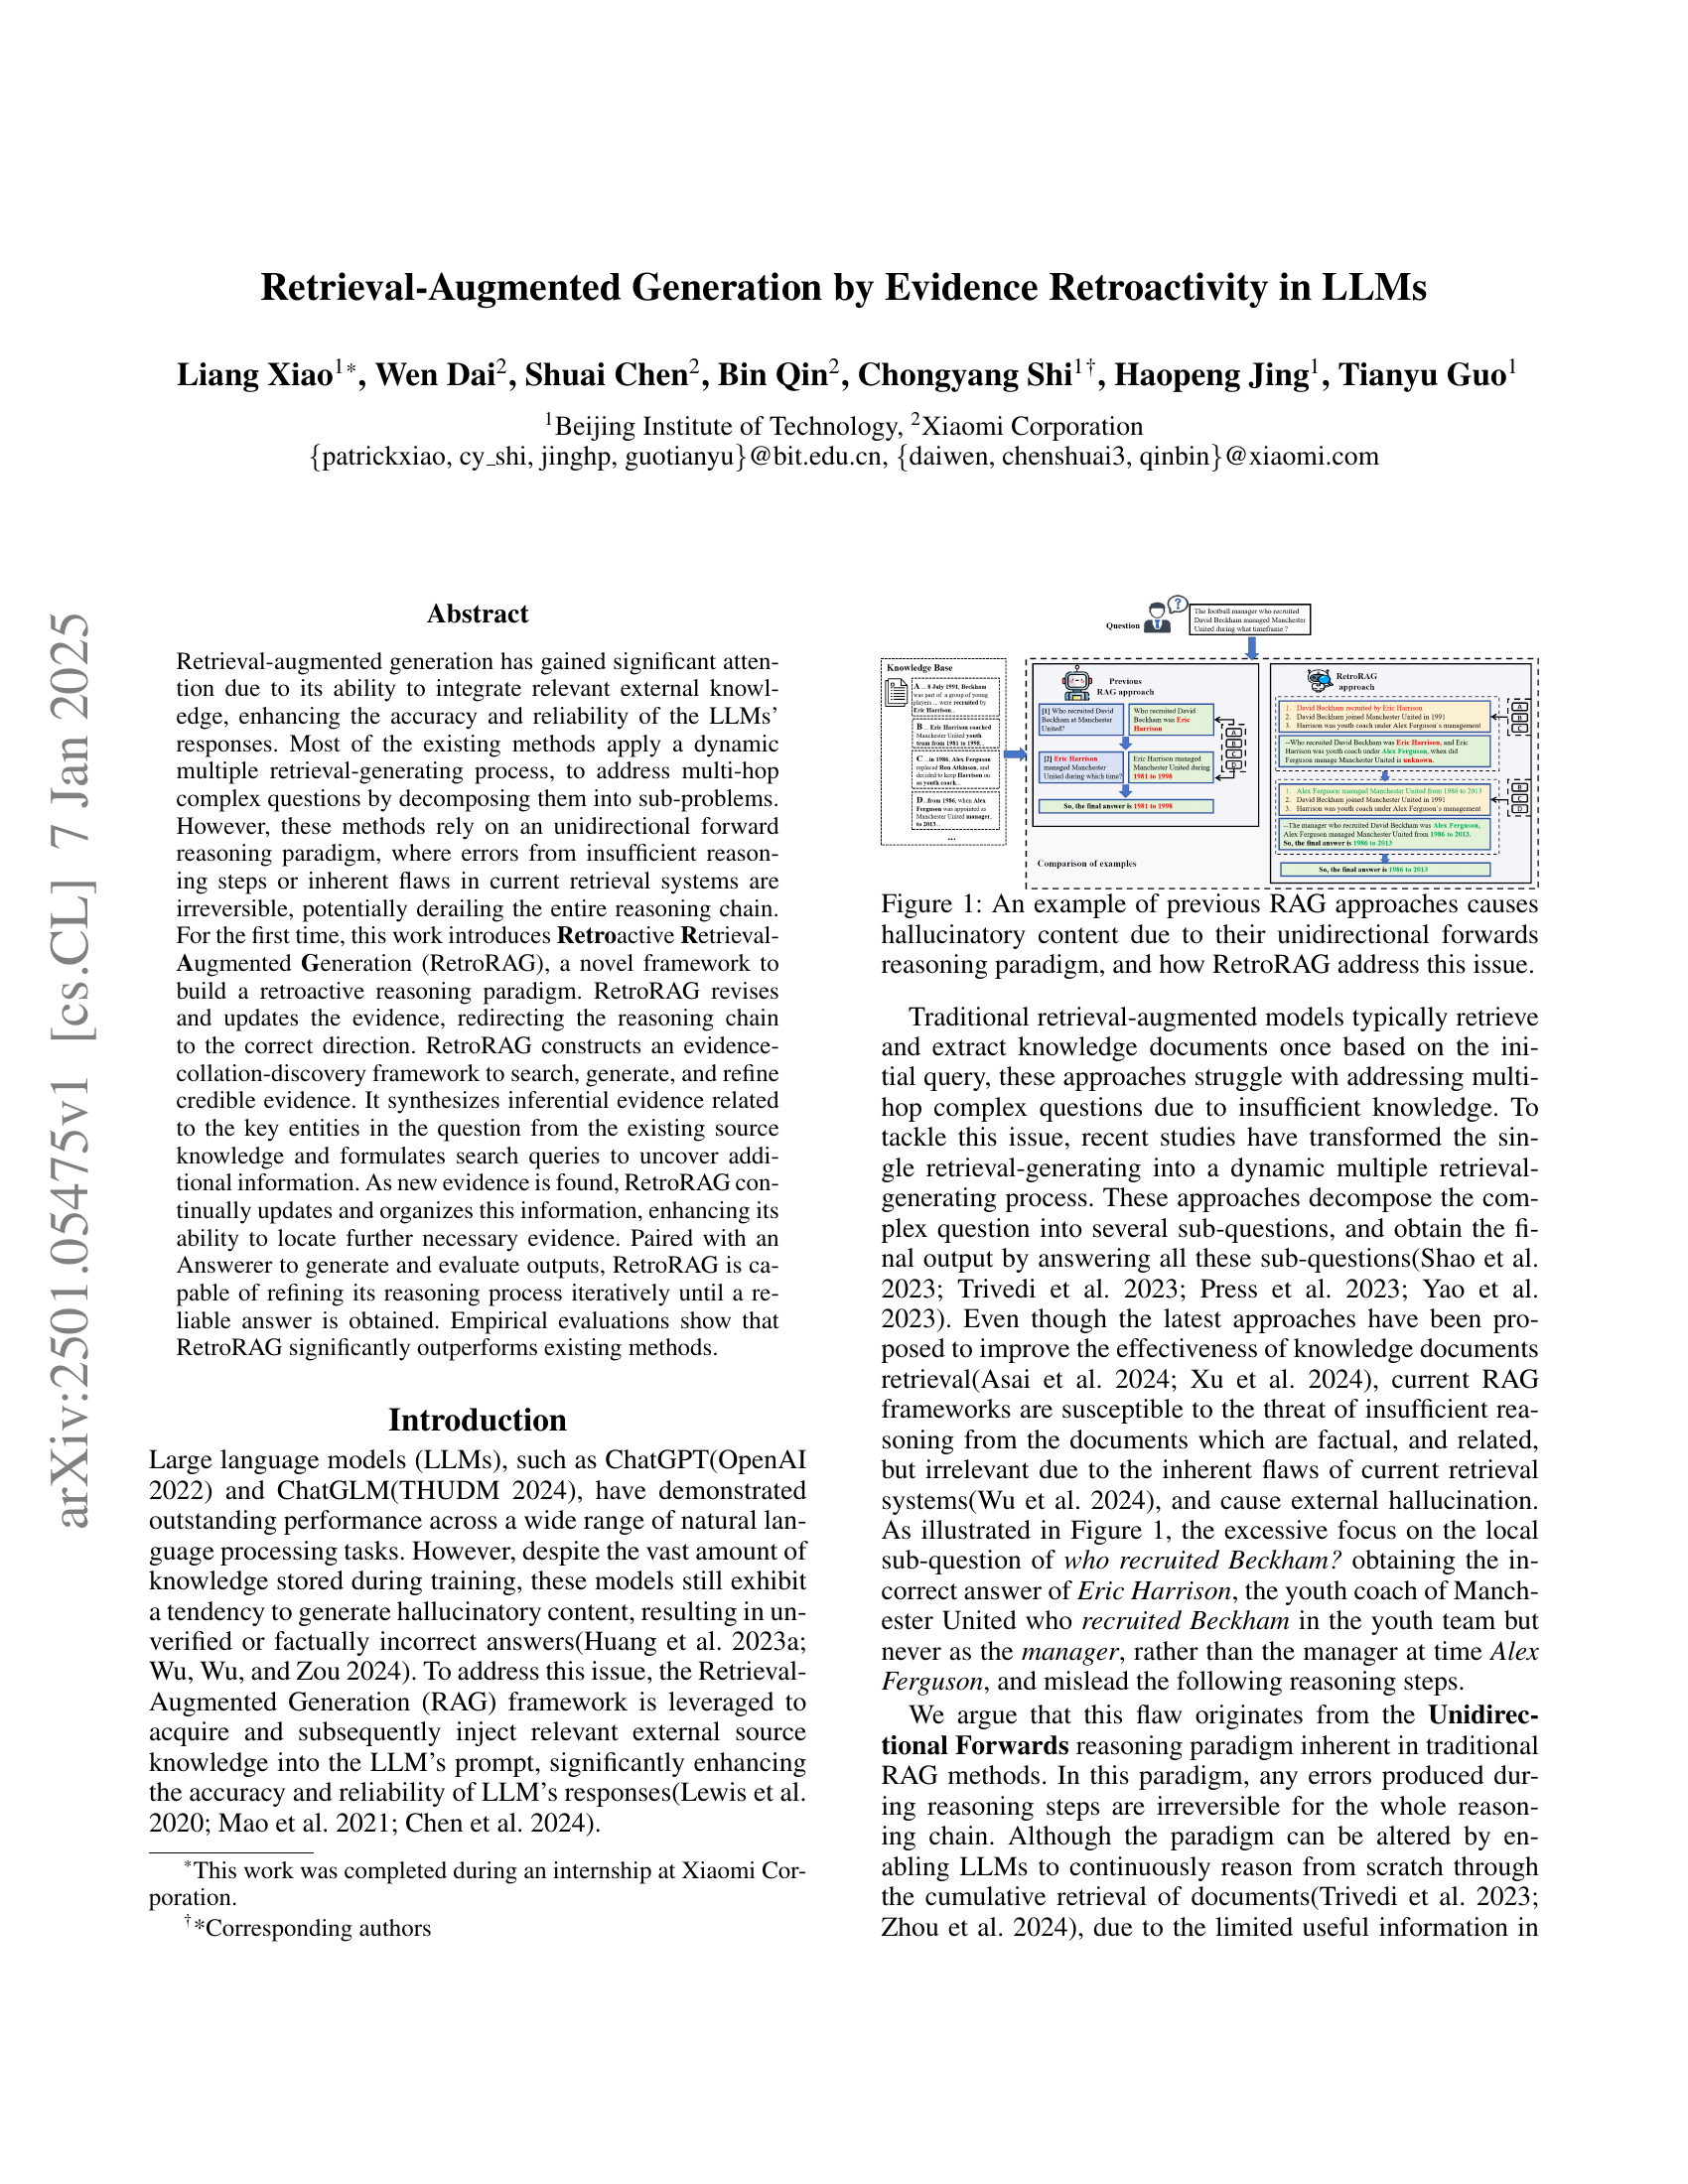

In [14]:
from PIL import Image
Image.open(image_path)

In [15]:
import pytesseract

ocr_text = pytesseract.image_to_string(Image.open(image_path))
print(ocr_text[:1000])

2501.05475v1 [cs.CL] 7 Jan 2025

arXiv

Retrieval-Augmented Generation by Evidence Retroactivity in LLMs

Liang Xiao!*, Wen Dai’, Shuai Chen’, Bin Qin’, Chongyang Shi'’, Haopeng Jing', Tianyu Guo

1

'Beijing Institute of Technology, 7Xiaomi Corporation
{patrickxiao, cy_shi, jinghp, guotianyu}@bit.edu.cn, {daiwen, chenshuai3, qinbin} @xiaomi.com

Abstract

Retrieval-augmented generation has gained significant atten-
tion due to its ability to integrate relevant external knowl-
edge, enhancing the accuracy and reliability of the LLMs’
responses. Most of the existing methods apply a dynamic
multiple retrieval-generating process, to address multi-hop
complex questions by decomposing them into sub-problems.
However, these methods rely on an unidirectional forward
reasoning paradigm, where errors from insufficient reason-
ing steps or inherent flaws in current retrieval systems are
irreversible, potentially derailing the entire reasoning chain.
For the first time, this work introduces Retro

In [16]:
real_text = extracted_docs[0]["pages"][0]["text"]  # page 1 of the same PDF

print("real text")
print(real_text[:500])
print("ocr text")
print(ocr_text[:500])

real text
Retrieval-Augmented Generation by Evidence Retroactivity in LLMs
Liang Xiao1*, Wen Dai2, Shuai Chen2, Bin Qin2, Chongyang Shi1†, Haopeng Jing1, Tianyu Guo1
1Beijing Institute of Technology, 2Xiaomi Corporation
{patrickxiao, cy shi, jinghp, guotianyu}@bit.edu.cn, {daiwen, chenshuai3, qinbin}@xiaomi.com
Abstract
Retrieval-augmented generation has gained significant atten-
tion due to its ability to integrate relevant external knowl-
edge, enhancing the accuracy and reliability of the LLMs’
respons
ocr text
2501.05475v1 [cs.CL] 7 Jan 2025

arXiv

Retrieval-Augmented Generation by Evidence Retroactivity in LLMs

Liang Xiao!*, Wen Dai’, Shuai Chen’, Bin Qin’, Chongyang Shi'’, Haopeng Jing', Tianyu Guo

1

'Beijing Institute of Technology, 7Xiaomi Corporation
{patrickxiao, cy_shi, jinghp, guotianyu}@bit.edu.cn, {daiwen, chenshuai3, qinbin} @xiaomi.com

Abstract

Retrieval-augmented generation has gained significant atten-
tion due to its ability to integrate relevant external knowl

**Conclusion:** OCR successfully recovered the title, authors, affiliations, and
abstract text with high accuracy. Minor differences were observed: OCR captured the
arXiv header stamp that the digital text layer omits, and a small number of character-
level errors occurred (e.g. a space misread as an underscore, a superscript digit
misread as "!"). This confirms the OCR pipeline works correctly and could be applied
to any scanned documents encountered in a real-world corpus.

In [17]:
with open("../processed/ocr_demo.json", "w") as f:
    json.dump({
        "source_pdf": "2501.05475v1.pdf",
        "real_text": real_text,
        "ocr_text": ocr_text
    }, f, indent=2)

### Cleaning text and removing header/footer
PDF text contains repeated header adn footer and broken line breraks from page layout. This step detects lines that repeat across many pages of the same document and removes them, normalises whitespave and rejoins broke  lines into clean paragraph

In [18]:
import re
from collections import Counter

In [19]:
def find_header_footer(pages, min_repeat_ratio=0.4):
    line_counts = Counter()
    for page in pages:
        lines = [l.strip() for l in page["text"].split("\n") if l.strip()]
        edge_lines = lines[:2] + lines[-2:]
        for line in set(edge_lines):
            if len(line) < 100:
                line_counts[line] +=1

    num_pages = len(pages)
    repeated = {line for line, count in line_counts.items()
               if count / num_pages >= min_repeat_ratio and num_pages >3}
    return repeated

In [20]:
def clean_text(full_text, repeated_lines):
    lines = full_text.split("\n")
    lines = [l for l in lines if l.strip() not in repeated_lines]
    text = "\n".join(lines)

    text = re.sub(r"-\n",'',text)
    text = re.sub(r"\n{3,}",'\n\n',text)
    text = re.sub(r"[ \t]+",' ',text)
    text = re.sub(r"(?<!\n)\n(?!\n)",' ',text)
    return text.strip()

In [21]:
cleaned_docs=[]
for doc in extracted_docs:
    repeated = find_header_footer(doc["pages"])
    cleaned = clean_text(doc["full_text"],repeated)
    cleaned_docs.append({
        "filename": doc["filename"],
        "num_pages": doc["num_pages"],
        "cleaned_text": cleaned,
        "removed_lines": list(repeated),
    })

print(len(cleaned_docs))
print(cleaned_docs[0]["removed_lines"])

130
[]


In [22]:
print(cleaned_docs[0]["cleaned_text"][:800])

Retrieval-Augmented Generation by Evidence Retroactivity in LLMs Liang Xiao1*, Wen Dai2, Shuai Chen2, Bin Qin2, Chongyang Shi1†, Haopeng Jing1, Tianyu Guo1 1Beijing Institute of Technology, 2Xiaomi Corporation {patrickxiao, cy shi, jinghp, guotianyu}@bit.edu.cn, {daiwen, chenshuai3, qinbin}@xiaomi.com Abstract Retrieval-augmented generation has gained significant attention due to its ability to integrate relevant external knowledge, enhancing the accuracy and reliability of the LLMs’ responses. Most of the existing methods apply a dynamic multiple retrieval-generating process, to address multi-hop complex questions by decomposing them into sub-problems. However, these methods rely on an unidirectional forward reasoning paradigm, where errors from insufficient reasoning steps or inherent fl


In [23]:
docs_with_removals = [d for d in cleaned_docs if len(d["removed_lines"]) > 0]
print("Docs with header/footer lines removed:", len(docs_with_removals))

if docs_with_removals:
    print("Example from:", docs_with_removals[0]["filename"])
    print(docs_with_removals[0]["removed_lines"])

Docs with header/footer lines removed: 37
Example from: 2603.20309v1.pdf
['Duyi Pan, Tianao Lou, Xin Li, Haoze Song, Yiwen Wu, Mengyi Deng, Mingyu Yang, and Wei Wang', 'BubbleRAG: Evidence-Driven Retrieval-Augmented Generation for Black-Box Knowledge Graphs']


In [24]:
with open("../processed/cleaned_docs.json","w") as f:
    json.dump(cleaned_docs, f)

### Splitting documents into chunks
Full docs are too long to feed AI and it takes long to search. This step splits each cleaned doc into overlapping chunks of a fixed size so the search can retrieve the specific relevant passage rather than an entire page.

In [25]:
def chunk_text(text, chunk_size=1000, overlap=200):
    chunks=[]
    start=0
    while start<len(text):
        end=start+chunk_size
        chunk=text[start:end]
        chunks.append(chunk)
        start+=chunk_size-overlap
    return chunks

In [26]:
def build_chunk(docs, chunk_size, overlap):
    all_chunks=[]
    for doc in docs:
        pieces = chunk_text(doc["cleaned_text"], chunk_size, overlap)
        for i, piece in enumerate(pieces):
            all_chunks.append({
                "chunk_id":f"{doc["filename"]}_{i}",
                "filename": doc["filename"],
                "chunk_index":i,
                "text": piece,
            })
    return all_chunks

In [27]:
chunks_1000=build_chunk(cleaned_docs, chunk_size=1000,overlap=200)
print(len(chunks_1000))
print(chunks_1000[0])

9621
{'chunk_id': '2501.05475v1.pdf_0', 'filename': '2501.05475v1.pdf', 'chunk_index': 0, 'text': 'Retrieval-Augmented Generation by Evidence Retroactivity in LLMs Liang Xiao1*, Wen Dai2, Shuai Chen2, Bin Qin2, Chongyang Shi1†, Haopeng Jing1, Tianyu Guo1 1Beijing Institute of Technology, 2Xiaomi Corporation {patrickxiao, cy shi, jinghp, guotianyu}@bit.edu.cn, {daiwen, chenshuai3, qinbin}@xiaomi.com Abstract Retrieval-augmented generation has gained significant attention due to its ability to integrate relevant external knowledge, enhancing the accuracy and reliability of the LLMs’ responses. Most of the existing methods apply a dynamic multiple retrieval-generating process, to address multi-hop complex questions by decomposing them into sub-problems. However, these methods rely on an unidirectional forward reasoning paradigm, where errors from insufficient reasoning steps or inherent flaws in current retrieval systems are irreversible, potentially derailing the entire reasoning chain. 

In [28]:
with open("../processed/chunks_1000.json", "w") as f:
    json.dump(chunks_1000, f)

In [29]:
chunks_500 = build_chunk(cleaned_docs, chunk_size=500, overlap=100)
print(len(chunks_500))

with open("../processed/chunks_500.json", "w") as f:
    json.dump(chunks_500, f)

19174


### Generating embeddings
An embedding converts the text chunks into vectors (list of numbers) that captures its meaning. Similar text gets similar vector.

In [30]:
!pip install sentence-transformers

In [31]:
from sentence_transformers import SentenceTransformer
import numpy as np

with open("../processed/chunks_1000.json") as f:
    chunks=json.load(f)

model = SentenceTransformer("all-MiniLM-L6-v2")

texts=[c["text"] for c in chunks]
embeddings = model.encode(texts, show_progress_bar=True, batch_size=64)

print(len(texts))
print(embeddings.shape)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/151 [00:00<?, ?it/s]

9621
(9621, 384)


In [32]:
np.save("../processed/embeddings_1000.npy", embeddings)
with open("../processed/chunks_1000_meta.json","w") as f:
    json.dump(chunks, f)

### Storing embeddings in vector database
Right now embeddings are just in .npy file, to actually search then we need a way to know which chunk stores the closest meaning to the question. That is what a vector databse does. It is used to find the nearest vectors.

In [33]:
!pip install chromadb

In [34]:
import chromadb

In [35]:
client=chromadb.PersistentClient("../processed/chromaDB")

In [36]:
# collection as in tabe fort one set of chunks
collection=client.get_or_create_collection(name="chunks_1000")

In [37]:
ids=[c["chunk_id"] for c in chunks]
documents = [c["text"] for c in chunks]
metadatas=[{"filename":c["filename"], "chunk_index": c["chunk_index"]} for c in chunks]
embedding_list=embeddings.tolist()

In [38]:
batch_size=5000
for i in range(0,len(ids),batch_size):
    collection.add(
        ids=ids[i:i+batch_size],
        embeddings=embedding_list[i:i+batch_size],
        documents=documents[i:i+batch_size],
        metadatas=metadatas[i:i+batch_size],
    )
    print(f"Added batch {i} to {i+batch_size}")

Added batch 0 to 5000
Added batch 5000 to 10000


In [39]:
query = "What is retrieval augmented generation?"
query_embedding = model.encode([query]).tolist()

results = collection.query(
    query_embeddings=query_embedding,
    n_results=3
)

for i, doc in enumerate(results["documents"][0]):
    print(f"result {i+1} (from {results['metadatas'][0][i]['filename']})")
    print(doc[:300])
    print()

result 1 (from 2507.12840v1.pdf)
5281/zenodo.10426927  [17] Es, S., James, J., Espinosa-Anke, L., and Schockaert, S. 2023. Ragas: Automated evaluation of retrieval augmented generation. arXiv  [Preprint]. (Sept. 26, 2023) [cited 2025 Mar 31]. Available from: https://arxiv.org/abs/2309.15217

result 2 (from 2411.11895v1.pdf)
ed generation. In Proceedings of the AAAI Conference on Artiﬁcial Intelligence, volume 38, pages 17754–17762, 2024. [29] Xiaohua Wang, Zhenghua Wang, Xuan Gao, Feiran Zhang, Yixin Wu, Zhibo Xu, Tianyuan Shi, Zhengyuan Wang, Shizheng Li, Qi Qian, et al. Searching for best practices in retrieval-augme

result 3 (from 2509.21336v1.pdf)
nding method for retrieval augmented generation. openreview, 2025. [35] R. Zhu, X. Liu, Z. Sun, Y. Wang, and W. Hu. Mitigating lost-in-retrieval problems in retrieval augmented multi-hop question answering. arXiv preprint arXiv:2502.14245, 2025. [36] Z. Yao, W. Qi, L. Pan, S. Cao, L. Hu, W. Liu, L. 



Initial search test with the query "what is retrieval augmented generation?" returned reference citiation list chunks rather than an explanation. This is a known limitation for semantic search.

In [40]:
print("Total items in collection:", collection.count())


Total items in collection: 9666


### Keyword search using BM25
BM25 is a keyword based search algorithm that searches documents by word overlap with the query, favouring rare, distinctive words and applying diminishing returns for repeated words. It matches actual words.

In [41]:
!pip install rank_bm25

In [42]:
from rank_bm25 import BM25Okapi

In [43]:
def tokenize(text):
    return re.findall(r"\b\w\b", text.lower())

tokenized_chunks=[tokenize(c["text"]) for c in chunks]

bm25 = BM25Okapi(tokenized_chunks)

print(len(tokenized_chunks))

9621


In [44]:
query = "What is retrieval augmented generation?"
query_embedding = model.encode([query]).tolist()

results = collection.query(
    query_embeddings=query_embedding,
    n_results=3
)

for i, doc in enumerate(results["documents"][0]):
    print(f"result {i+1} (from {results['metadatas'][0][i]['filename']})")
    print(doc[:300])
    print()

result 1 (from 2507.12840v1.pdf)
5281/zenodo.10426927  [17] Es, S., James, J., Espinosa-Anke, L., and Schockaert, S. 2023. Ragas: Automated evaluation of retrieval augmented generation. arXiv  [Preprint]. (Sept. 26, 2023) [cited 2025 Mar 31]. Available from: https://arxiv.org/abs/2309.15217

result 2 (from 2411.11895v1.pdf)
ed generation. In Proceedings of the AAAI Conference on Artiﬁcial Intelligence, volume 38, pages 17754–17762, 2024. [29] Xiaohua Wang, Zhenghua Wang, Xuan Gao, Feiran Zhang, Yixin Wu, Zhibo Xu, Tianyuan Shi, Zhengyuan Wang, Shizheng Li, Qi Qian, et al. Searching for best practices in retrieval-augme

result 3 (from 2509.21336v1.pdf)
nding method for retrieval augmented generation. openreview, 2025. [35] R. Zhu, X. Liu, Z. Sun, Y. Wang, and W. Hu. Mitigating lost-in-retrieval problems in retrieval augmented multi-hop question answering. arXiv preprint arXiv:2502.14245, 2025. [36] Z. Yao, W. Qi, L. Pan, S. Cao, L. Hu, W. Liu, L. 



BM25 keyword search returned the same reference list chunjs as semantic search. The phrase "retrieval augment generation" appears densely in citation. This shows both retrieval methods can independently fail on queries that overlap heavily with common paper/citation titles.

In [45]:
query2 = "how do models avoid making up false information"
tokenized_query2 = tokenize(query2)
scores2 = bm25.get_scores(tokenized_query2)
top_indices2 = scores2.argsort()[::-1][:3]

for rank, idx in enumerate(top_indices2):
    print(f"Result {rank+1} (from {chunks[idx]['filename']}, score={scores2[idx]:.2f})")
    print(chunks[idx]["text"][:300])
    print()

Result 1 (from 2412.16701v3.pdf, score=0.00)
 is such that it can be reasonably supposed to have arisen from random sampling. London, Edinburgh, Dublin Philos. Mag. J. Sci. 1900, 50, 157–175. 84. Neyman, J.; Pearson, E.S. IX. On the problem of the most efficient tests of statistical hypotheses. Philos. Trans. R. Soc. London. Ser. Contain. Pap.

Result 2 (from 2601.08670v1.pdf, score=0.00)
lity of Fixed β: While specific fixed values can achieve high scores on individual tasks (e.g., β = 0.25 on Llama-NQ or β = 0.75 on Llama-HotpotQA), they are inconsistent. A value that works well for one dataset may fail on another (e.g., β = 0.75 drops significantly on Mistral-HotpotQA compared to 

Result 3 (from 2601.08670v1.pdf, score=0.00)
 smoothly compressing large sparse scores. Reranker scores (BGE reranker). We use BAAI/bge-reranker-v2-m3 via FlagReranker. With normalize=True, the reranker applies a sigmoid to map raw logits to [0, 1]: rrer k = σ(zk) = 1 1 + exp(−zk). (6) As above, we clip t

In [46]:
query2 = "how do models avoid making up false information"
query2_embedding = model.encode([query2]).tolist()

results2 = collection.query(
    query_embeddings=query2_embedding,
    n_results=3
)

for i, doc in enumerate(results2["documents"][0]):
    print(f"Result {i+1} (from {results2['metadatas'][0][i]['filename']})")
    print(doc[:300])
    print()

Result 1 (from 2412.12300v3.pdf)
 question w/o including disclaimers or addressing the ambiguous nature of the request. Falsepresup. The model either: (1) explicitly refuses to answer the question or (2) challenges the premise of the request, points out any incorrect assumptions, and may provide an answer based on a corrected premi

Result 2 (from 2411.08891v4.pdf)
 [5, 6, 7]. However, even with significant increases in model size and the expansion of training datasets, it remains infeasible for LLMs to encode all possible knowledge within their parameters. As a result, the outputs produced by LLMs may not consistently be reliable for important human decision-

Result 3 (from 2412.12300v3.pdf)
wer": """I don’t know.""", "ground_truth": "Diversity, Equity, and Inclusion (DEI) initiatives, health, wellness, family resources.", "output": { "reason": "The answer indicates a lack of knowledge regarding the answer.", "verdict": "-1", }, } ], input_keys=["answer", "ground_truth"], output_key=

**Observation:** For the query "how do models avoid making up false information"
(deliberately avoiding the technical term "hallucination"), BM25 keyword search
completely failed (all scores 0.00, returning unrelated statistical/reranking content),
since it requires literal word overlap. Semantic search succeeded, returning chunks
about false presuppositions, models answering "I don't know" instead of guessing, and
LLM knowledge limitations, all directly relevant to hallucination/factuality, despite
no shared vocabulary with the query. This demonstrates the core strength of
embedding-based search: understanding meaning rather than exact wording.

### Hybrid search
It combines semantic search and BM25 keyword search into a single ranking. 

In [47]:
import numpy as np

In [48]:
def normalize(score):
    score = np.array(score)
    if score.max() == score.min():
        return np.zeros_like(score)
    return (score-score.min()) / (score.max() - score.min())

In [49]:
def hybrid_search(query, top_k=5, alpha=0.5):
    #getting all chunks scored
    query_embedding = model.encode([query])
    all_results = collection.query(query_embeddings=query_embedding.tolist(), n_results=len(chunks))
    #building lookup
    semantic_distances = {cid: dist for cid, dist in zip(all_results["ids"][0], all_results["distances"][0])}
    
    semantic_scores_ordered =[1 - semantic_distances.get(c["chunk_id"],1) for c in chunks]

    tokenized_query = tokenize(query)
    bm25_scores_ordered = bm25.get_scores(tokenized_query)

    sem_norm = normalize(semantic_scores_ordered)
    bm25_norm = normalize(bm25_scores_ordered)

    combined = alpha * sem_norm + (1-alpha) * bm25_norm

    top_indices = np.argsort(combined)[::-1][:top_k]

    results =[]
    for idx in top_indices:
        results.append({
            "filename": chunks[idx]["filename"],
            "text": chunks[idx]["text"],
            "combined_score": combined[idx],
            "semantic_score": sem_norm[idx],
            "bm25_score": bm25_norm[idx],
        })
    return results

In [50]:
results = hybrid_search("how do models avoid making up false information", top_k=3, alpha=0.5)

for i, r in enumerate(results):
    print(f"Result {i+1} (from {r['filename']}, combined={r['combined_score']:.3f}, sem={r['semantic_score']:.3f}, bm25={r['bm25_score']:.3f})")
    print(r["text"][:300])
    print()

Result 1 (from 2412.12300v3.pdf, combined=0.500, sem=1.000, bm25=0.000)
 question w/o including disclaimers or addressing the ambiguous nature of the request. Falsepresup. The model either: (1) explicitly refuses to answer the question or (2) challenges the premise of the request, points out any incorrect assumptions, and may provide an answer based on a corrected premi

Result 2 (from 2410.15944v1.pdf, combined=0.488, sem=0.976, bm25=0.000)
ng system (Windows, macOS, or Linux) and follow the instructions for installation. 2. Install the Python Extension in VSCode – Open VSCode. – Click on the Extensions tab on the left-hand side (it looks like a square with four pieces). – In the Extensions Marketplace, search for Python. – Install the

Result 3 (from 2505.04846v1.pdf, combined=0.488, sem=0.976, bm25=0.000)
 (OLCF). In the November 2024 Top500 list [71], Polaris is ranked #47 with a peak of 34 PFLOPS and 8

Table 6: GPU supercomputing systems used for evaluation. Polaris Sunspot Front

In [51]:
results2 = hybrid_search("What is retrieval augmented generation?", top_k=3, alpha=0.5)

for i, r in enumerate(results2):
    print(f"Result {i+1} (from {r['filename']}, combined={r['combined_score']:.3f}, sem={r['semantic_score']:.3f}, bm25={r['bm25_score']:.3f})")
    print(r["text"][:300])
    print()

Result 1 (from 2507.12840v1.pdf, combined=0.500, sem=1.000, bm25=0.000)
5281/zenodo.10426927  [17] Es, S., James, J., Espinosa-Anke, L., and Schockaert, S. 2023. Ragas: Automated evaluation of retrieval augmented generation. arXiv  [Preprint]. (Sept. 26, 2023) [cited 2025 Mar 31]. Available from: https://arxiv.org/abs/2309.15217

Result 2 (from 2411.11895v1.pdf, combined=0.451, sem=0.902, bm25=0.000)
ed generation. In Proceedings of the AAAI Conference on Artiﬁcial Intelligence, volume 38, pages 17754–17762, 2024. [29] Xiaohua Wang, Zhenghua Wang, Xuan Gao, Feiran Zhang, Yixin Wu, Zhibo Xu, Tianyuan Shi, Zhengyuan Wang, Shizheng Li, Qi Qian, et al. Searching for best practices in retrieval-augme

Result 3 (from 2509.21336v1.pdf, combined=0.443, sem=0.885, bm25=0.000)
nding method for retrieval augmented generation. openreview, 2025. [35] R. Zhu, X. Liu, Z. Sun, Y. Wang, and W. Hu. Mitigating lost-in-retrieval problems in retrieval augmented multi-hop question answering. arXiv preprint 

### Rank based normalization
Min-max normalization is sensitive to outliers (a single very high-scoring chunk
compresses all others toward 0). Rank-based normalization instead converts scores
into their rank position, then normalizes that rank — making the combination more
robust to outlier scores from either method.

In [52]:
def rank_normalize(scores):
    scores = np.array(scores)
    n = len(scores)

    ranks = np.argsort(np.argsort(-scores))

    normalized = 1 - (ranks / (n - 1))
    return normalized

In [53]:
def hybrid_search_v2(query, top_k=5, alpha=0.5):
    #getting all chunks scored
    query_embedding = model.encode([query])
    all_results = collection.query(query_embeddings=query_embedding.tolist(), n_results=len(chunks))
    #building lookup
    semantic_distances = {cid: dist for cid, dist in zip(all_results["ids"][0], all_results["distances"][0])}
    
    semantic_scores_ordered =[1 - semantic_distances.get(c["chunk_id"],1) for c in chunks]

    tokenized_query = tokenize(query)
    bm25_scores_ordered = bm25.get_scores(tokenized_query)

    sem_norm = rank_normalize(semantic_scores_ordered)
    bm25_norm = rank_normalize(bm25_scores_ordered)

    combined = alpha * sem_norm + (1-alpha) * bm25_norm

    top_indices = np.argsort(combined)[::-1][:top_k]

    results =[]
    for idx in top_indices:
        results.append({
            "filename": chunks[idx]["filename"],
            "text": chunks[idx]["text"],
            "combined_score": combined[idx],
            "semantic_score": sem_norm[idx],
            "bm25_score": bm25_norm[idx],
        })
    return results

In [54]:
print("Query: 'how do models avoid making up false information'\n")
results = hybrid_search_v2("how do models avoid making up false information", top_k=3, alpha=0.5)
for i, r in enumerate(results):
    print(f"Result {i+1} (from {r['filename']}, combined={r['combined_score']:.3f}, sem={r['semantic_score']:.3f}, bm25={r['bm25_score']:.3f})")
    print(r["text"][:300])
    print()

print("\nQuery: 'What is retrieval augmented generation?'\n")
results2 = hybrid_search_v2("What is retrieval augmented generation?", top_k=3, alpha=0.5)
for i, r in enumerate(results2):
    print(f"Result {i+1} (from {r['filename']}, combined={r['combined_score']:.3f}, sem={r['semantic_score']:.3f}, bm25={r['bm25_score']:.3f})")
    print(r["text"][:300])
    print()

Query: 'how do models avoid making up false information'

Result 1 (from 2510.24402v1.pdf, combined=0.996, sem=0.994, bm25=0.998)
ation. It is the proportion of ground-truth claims that are covered by the retrieved chunks. A low score indicates the retriever failed to find critical pieces of evidence. Diagnostic Generator Metrics: • Faithfulness: Measures whether the generator is inventing information. Faithfulness is calculat

Result 2 (from 2510.24402v1.pdf, combined=0.991, sem=0.988, bm25=0.994)
arent model can achieve highly competitive results. For accounting firms and corporate finance departments, this has profound implications. It offers a path to developing powerful analytical tools without incurring high operational costs or vendor lock-in. More importantly, a transparent model is in

Result 3 (from 2510.24402v1.pdf, combined=0.990, sem=0.982, bm25=0.998)
oriously long, dense, and contain a mix of narrative text, numerical data, and structured tables, making them an ideal and

### Metadata Filtering
metadata filtering allows narrowing search results using structured attributes rather than relevance alone. Its useful for queries which asks to search in specific page or category. We connect the arxiv metadata collected in step3 to our chunks using filename and add filtering.

In [55]:
with open("../data/arxiv_metadata.json") as f:
    arxiv_meta = json.load(f)

#build loolup using filename
meta_lookup = {m["filename"]: m for m in arxiv_meta}

missing = [c["filename"] for c in chunks if c["filename"] not in meta_lookup]
print("chunks missing:", len(missing))
print("example", list(meta_lookup.values())[0])

chunks missing: 0
example {'id': '2411.18583v1', 'title': 'Automated Literature Review Using NLP Techniques and LLM-Based Retrieval-Augmented Generation', 'author': ['Nurshat Fateh Ali', 'Md. Mahdi Mohtasim', 'Shakil Mosharrof', 'T. Gopi Krishna'], 'published': '2024-11-27', 'category': 'cs.CL', 'filename': '2411.18583v1.pdf'}


In [56]:
def filter_chunks_by_year(min_year):
    # keeping chunks from paper published in or after mininum year
    filtered = []
    for c in chunks:
        year = int(meta_lookup[c["filename"]]["published"][:4])
        if year>=min_year:
            filtered.append(c)
    return filtered

In [57]:
recent_chunks = filter_chunks_by_year(2024)
print("chunks from 2024 onwards: ", len(recent_chunks))
print(len(chunks))

chunks from 2024 onwards:  9136
9621


### Reranking
reranking rescores the top chunks picked by hybrid search using cross encoder model. It looks at the question and chunk together to figure out relevant answer. It is slowed so it is applied to the shortlist.

In [58]:
from sentence_transformers import CrossEncoder

reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

In [59]:
def rerank(query, candidates, top_k=3):
    pairs = [[query,c["text"]] for c in candidates]
    scores = reranker.predict(pairs)

    for c, score in zip(candidates,scores):
        c["rerank_score"]=score

    reranked = sorted(candidates, key=lambda c: c["rerank_score"], reverse=True)
    return reranked[:top_k]

In [60]:
query = "What is retrieval augmented generation?"
# getting more than we need, so reranker has choices
candidates = hybrid_search_v2(query, top_k=10, alpha=0.5)  

reranked_results = rerank(query, candidates, top_k=3)

for i, r in enumerate(reranked_results):
    print(f"Result {i+1} (from {r['filename']}, rerank_score={r['rerank_score']:.3f})")
    print(r["text"][:300])
    print()

Result 1 (from 2501.05475v1.pdf, rerank_score=7.439)
Retrieval-Augmented Generation by Evidence Retroactivity in LLMs Liang Xiao1*, Wen Dai2, Shuai Chen2, Bin Qin2, Chongyang Shi1†, Haopeng Jing1, Tianyu Guo1 1Beijing Institute of Technology, 2Xiaomi Corporation {patrickxiao, cy shi, jinghp, guotianyu}@bit.edu.cn, {daiwen, chenshuai3, qinbin}@xiaomi.c

Result 2 (from 2510.24402v1.pdf, rerank_score=6.029)
 Bi, Yi Dai, Jiawei Sun, Meng Wang, and Haofen Wang. Retrieval-Augmented Generation for Large Language Models: A Survey. https://arxiv.org/abs/2312.10997v5, December 2023a. Patrick Lewis, Ethan Perez, Aleksandra Piktus, Fabio Petroni, Vladimir Karpukhin, Naman Goyal, Heinrich Küttler, Mike Lewis, We

Result 3 (from 2510.24402v1.pdf, rerank_score=4.785)
d Generation in LLMs. https://arxiv.org/abs/2407.02485v1, July 2024. Aditi Singh, Abul Ehtesham, Saket Kumar, and Tala Talaei Khoei. Agentic Retrieval-Augmented Generation: A Survey on Agentic RAG. https://arxiv.org/abs/2501.09136v3, Jan

In [61]:
query2 = "how do models avoid making up false information"
candidates2 = hybrid_search_v2(query2, top_k=10, alpha=0.5)

reranked_results2 = rerank(query2, candidates2, top_k=3)

for i, r in enumerate(reranked_results2):
    print(f"Result {i+1} (from {r['filename']}, rerank_score={r['rerank_score']:.3f})")
    print(r["text"][:300])
    print()

Result 1 (from 2502.00306v2.pdf, rerank_score=-3.852)
posure to adversaries aiming to extract sensitive information from the underlying set of documents. Apart from adversaries that can inject their own documents via poisoning [6], prompt-stealing adversaries [18] may be able to infer the presence of retrieved documents present in the model’s context v

Result 2 (from 2510.24402v1.pdf, rerank_score=-4.614)
ation. It is the proportion of ground-truth claims that are covered by the retrieved chunks. A low score indicates the retriever failed to find critical pieces of evidence. Diagnostic Generator Metrics: • Faithfulness: Measures whether the generator is inventing information. Faithfulness is calculat

Result 3 (from 2502.00306v2.pdf, rerank_score=-4.906)
∗, S) = ( 1, if 𝑑∗∈D 0, if 𝑑∗∉D The very use of a RAG system implies that the generative model’s knowledge is not wholly self-contained. This reliance often stems from the need to reference specific, potentially sensitive information 

### Query expansion
Query expansion adds related words or phrases to a search query so it increases the chance of matching relevant chunks that use different wording than the original question.We will expand manually with a synonym dictionary , later when we have LLM, we can expand queries automatically.

In [62]:
synonym_map = {
    "false information": ["hallucination", "factuality", "faithfulness"],
    "retrieval augmented generation": ["RAG", "retrieve then generate"],
}

def expand_query(query):
    expanded = query
    for phrase, synonym in synonym_map.items():
        if phrase in query.lower():
            expanded += " " + " ".join(synonym)
    return expanded

In [63]:
query = "how do models avoid making up false information"
expanded = expand_query(query)

print("Original:", query)
print("Expanded:", expanded)


Original: how do models avoid making up false information
Expanded: how do models avoid making up false information hallucination factuality faithfulness


In [64]:
results_before = hybrid_search_v2(query, top_k=3, alpha=0.5)
results_after = hybrid_search_v2(expanded, top_k=3, alpha=0.5)

print("BEFORE expansion")
for r in results_before:
    print(r["filename"], "-", r["text"][:150])

print("\nAFTER expansion")
for r in results_after:
    print(r["filename"], "-", r["text"][:150])

BEFORE expansion
2510.24402v1.pdf - ation. It is the proportion of ground-truth claims that are covered by the retrieved chunks. A low score indicates the retriever failed to find critic
2510.24402v1.pdf - arent model can achieve highly competitive results. For accounting firms and corporate finance departments, this has profound implications. It offers 
2510.24402v1.pdf - oriously long, dense, and contain a mix of narrative text, numerical data, and structured tables, making them an ideal and realistic challenge for RAG

AFTER expansion
2510.24402v1.pdf - ation. It is the proportion of ground-truth claims that are covered by the retrieved chunks. A low score indicates the retriever failed to find critic
2510.24402v1.pdf - orrect answers, and lack the ability to access up-to-date or verifiable knowledge beyond their training data (Zhang et al., 2023b). These issues are e
2502.00306v2.pdf - ∗, S) = ( 1, if 𝑑∗∈D 0, if 𝑑∗∉D The very use of a RAG system implies that the generative model’s 

### Context retrieval
this combines hybrid search and reranking in one funtion which return best chunks formatted as content text. that will be handed to LLM for answer.

In [65]:
import re

def is_reference_heavy(text, threshold=3):
    """Heuristic: count citation markers like [12] or (2023) - if there are many, it's likely a reference list."""
    citation_markers = re.findall(r"\[\d+\]|\(\d{4}[a-z]?\)", text)
    return len(citation_markers) >= threshold

In [66]:
def get_context(query, top_k=3):
    candidates = hybrid_search_v2(query, top_k=15, alpha=0.5)  # get more, filter some out
    candidates = [c for c in candidates if not is_reference_heavy(c["text"])]
    best_chunks = rerank(query, candidates, top_k=top_k)

    context_text = ""
    for i, c in enumerate(best_chunks):
        context_text += f"[Source {i+1}: {c['filename']}]\n{c['text']}\n\n"

    return context_text, best_chunks

In [67]:
query = "What is retrieval augmented generation?"
context_text, sources = get_context(query)

print(context_text[:1000])

[Source 1: 2501.05475v1.pdf]
Retrieval-Augmented Generation by Evidence Retroactivity in LLMs Liang Xiao1*, Wen Dai2, Shuai Chen2, Bin Qin2, Chongyang Shi1†, Haopeng Jing1, Tianyu Guo1 1Beijing Institute of Technology, 2Xiaomi Corporation {patrickxiao, cy shi, jinghp, guotianyu}@bit.edu.cn, {daiwen, chenshuai3, qinbin}@xiaomi.com Abstract Retrieval-augmented generation has gained significant attention due to its ability to integrate relevant external knowledge, enhancing the accuracy and reliability of the LLMs’ responses. Most of the existing methods apply a dynamic multiple retrieval-generating process, to address multi-hop complex questions by decomposing them into sub-problems. However, these methods rely on an unidirectional forward reasoning paradigm, where errors from insufficient reasoning steps or inherent flaws in current retrieval systems are irreversible, potentially derailing the entire reasoning chain. For the first time, this work introduces Retroactive RetrievalAugmente

In [68]:
%pip install ollama

Note: you may need to restart the kernel to use updated packages.


In [69]:
import ollama

response = ollama.chat(model="llama3.2:3b", messages=[
    {"role": "user", "content": "Say hello in one sentence."}
])

print(response["message"]["content"])

Hello.


### Improved Source citations
citations aee upgraded to nclude a page number and a short quoted snippet so an answer can be verified against the original document. page numbers are recovered from step 4 matching chunk text back to original page

In [70]:
# Build a lookup: filename -> list of (page_num, page_text)
page_lookup = {doc["filename"]: doc["pages"] for doc in extracted_docs}

def find_page(filename, chunk_text, sample_len=80):
    # Guess which page a chunk came from, by matching a short sample of its text.
    sample = chunk_text[:sample_len].strip()
    pages = page_lookup.get(filename, [])
    for page in pages:
        if sample[:40] in page["text"]:  # just check first 40 chars for a loose match
            return page["page_num"]
    return None  # could not confidently match

In [71]:
def format_citation(chunk):
    page = find_page(chunk["filename"], chunk["text"])
    snippet = chunk["text"][:150].strip() + "..."
    page_str = f"page {page}" if page else "page unknown"
    return f"{chunk['filename']} ({page_str}): \"{snippet}\""

In [72]:
# Test it on our last set of sources
for s in sources:
    print(format_citation(s))
    print()

2501.05475v1.pdf (page 1): "Retrieval-Augmented Generation by Evidence Retroactivity in LLMs Liang Xiao1*, Wen Dai2, Shuai Chen2, Bin Qin2, Chongyang Shi1†, Haopeng Jing1, Tianyu..."

2510.24402v1.pdf (page 16): "Bi, Yi Dai, Jiawei Sun, Meng Wang, and Haofen Wang. Retrieval-Augmented Generation for Large Language Models: A Survey. https://arxiv.org/abs/2312.10..."

2510.24402v1.pdf (page 18): ", and Jiliang Tang. Retrieval-Augmented Generation with Graphs (GraphRAG), January 2025. Xiangrong Zhu, Yuexiang Xie, Yi Liu, Yaliang Li, and Wei Hu...."



### RAG pipeline
It combines context retrieval with LLM into one fucntion. when given a question, it retrieves relevant chunks, builds a prompt instructing the LLM to answer only based on that context and returns answer along with which sources

In [73]:
def rag_answer(query, top_k=3):
    context_text, sources = get_context(query, top_k=top_k)

    prompt = f"""Answer the question using ONLY the context below. 
If the answer is not in the context, say "I don't know based on the provided documents."
Do not use any outside knowledge.

Context:
{context_text}

Question: {query}

Answer:"""

    response = ollama.chat(model="llama3.2:3b", messages=[
        {"role": "user", "content": prompt}
    ])

    answer = response["message"]["content"]

    print("ANSWER:")
    print(answer)
    print("\nSOURCES:")
    for s in sources:
        print("-", format_citation(s))

    return answer, sources

answer, sources = rag_answer("What is retrieval augmented generation?")

ANSWER:
Retrieval-Augmented Generation (RAG) is a method that integrates relevant external knowledge to enhance the accuracy and reliability of Large Language Models (LLMs) responses.

SOURCES:
- 2501.05475v1.pdf (page 1): "Retrieval-Augmented Generation by Evidence Retroactivity in LLMs Liang Xiao1*, Wen Dai2, Shuai Chen2, Bin Qin2, Chongyang Shi1†, Haopeng Jing1, Tianyu..."
- 2510.24402v1.pdf (page 16): "Bi, Yi Dai, Jiawei Sun, Meng Wang, and Haofen Wang. Retrieval-Augmented Generation for Large Language Models: A Survey. https://arxiv.org/abs/2312.10..."
- 2510.24402v1.pdf (page 18): ", and Jiliang Tang. Retrieval-Augmented Generation with Graphs (GraphRAG), January 2025. Xiangrong Zhu, Yuexiang Xie, Yi Liu, Yaliang Li, and Wei Hu...."


In [74]:
context_text, sources = get_context("What is retrieval augmented generation?")

prompt = f"""Answer the question using ONLY the context below. 
If the answer is not in the context, say "I don't know based on the provided documents."
Do not use any outside knowledge.

Context:
{context_text}

Question: What is retrieval augmented generation?

Answer:"""

print(prompt)

Answer the question using ONLY the context below. 
If the answer is not in the context, say "I don't know based on the provided documents."
Do not use any outside knowledge.

Context:
[Source 1: 2501.05475v1.pdf]
Retrieval-Augmented Generation by Evidence Retroactivity in LLMs Liang Xiao1*, Wen Dai2, Shuai Chen2, Bin Qin2, Chongyang Shi1†, Haopeng Jing1, Tianyu Guo1 1Beijing Institute of Technology, 2Xiaomi Corporation {patrickxiao, cy shi, jinghp, guotianyu}@bit.edu.cn, {daiwen, chenshuai3, qinbin}@xiaomi.com Abstract Retrieval-augmented generation has gained significant attention due to its ability to integrate relevant external knowledge, enhancing the accuracy and reliability of the LLMs’ responses. Most of the existing methods apply a dynamic multiple retrieval-generating process, to address multi-hop complex questions by decomposing them into sub-problems. However, these methods rely on an unidirectional forward reasoning paradigm, where errors from insufficient reasoning steps o

In [75]:
answer, sources = rag_answer("What is retrieval augmented generation?")

ANSWER:
Retrieval-Augmented Generation (RAG) is a method that integrates relevant external knowledge to enhance the accuracy and reliability of Large Language Model's (LLM) responses.

SOURCES:
- 2501.05475v1.pdf (page 1): "Retrieval-Augmented Generation by Evidence Retroactivity in LLMs Liang Xiao1*, Wen Dai2, Shuai Chen2, Bin Qin2, Chongyang Shi1†, Haopeng Jing1, Tianyu..."
- 2510.24402v1.pdf (page 16): "Bi, Yi Dai, Jiawei Sun, Meng Wang, and Haofen Wang. Retrieval-Augmented Generation for Large Language Models: A Survey. https://arxiv.org/abs/2312.10..."
- 2510.24402v1.pdf (page 18): ", and Jiliang Tang. Retrieval-Augmented Generation with Graphs (GraphRAG), January 2025. Xiangrong Zhu, Yuexiang Xie, Yi Liu, Yaliang Li, and Wei Hu...."


### Hallucination detection
after generating an answer we check if its from retrievd context or not. method 1 is a simple word overlap check and method 2 is asking LLM to judge whether the answer if supported.

In [76]:
def check_overlap(answer, context_text):
    # what parts of answer's meaningful word appears in context retrieved
    answer_words = set(tokenize(answer))
    context_words=set(tokenize(context_text))

    #ignore common filler words
    stopwords = {"the", "a", "an", "is", "are", "was", "were", "to", "of", "in", "and", "or", "for", "on", "with", "by", "this", "that", "it", "as", "be"}
    answer_words = answer_words - stopwords

    if not answer_words:
        return 1.0

    overlap = answer_words & context_words
    return len(overlap) / len(answer_words)

In [77]:
overlap_score = check_overlap(answer, context_text)
print(f"Overlap score: {overlap_score:.2f}")

if overlap_score < 0.5:
    print("low overlap with context, possible hallucination.")
else:
    print("Answer appears well-grounded in context.")

Overlap score: 0.00
low overlap with context, possible hallucination.


In [78]:
def llm_check_grounded(answer, context_text):
    check_prompt = f"""Context:
{context_text}

Answer: {answer}

Is the Answer fully supported by the Context above? Reply with only one word: YES or NO."""

    response = ollama.chat(model="llama3.2:3b", messages=[
        {"role": "user", "content": check_prompt}
    ])
    return response["message"]["content"].strip()

verdict = llm_check_grounded(answer, context_text)
print("LLM grounding check:", verdict)

LLM grounding check: YES.


### Question Answer test set
part 1: load BEIR's built in queries which tells us exactly which documents are cirrect for each question
part 2: create a small test set from arxiv PDF

In [79]:
with open("../data/scifact/queries.jsonl") as f:
    beir_queries = [json.loads(line) for line in f]

In [80]:
print("number of queries:", len(beir_queries))
print(beir_queries[0])

number of queries: 1109
{'_id': '0', 'text': '0-dimensional biomaterials lack inductive properties.', 'metadata': {}}


In [81]:
import os
print(os.listdir("../data/scifact/qrels"))

['train.tsv', 'test.tsv']


In [82]:
import csv

In [83]:
qrels = {} # for each question ID, a set of doc id which have answers

with open("../data/scifact/qrels/test.tsv") as f:
    reader = csv.DictReader(f, delimiter="\t")
    for row in reader:
        qid = row["query-id"]
        doc_id = row["corpus-id"]
        qrels.setdefault(qid, set()).add(doc_id)

In [84]:
print('number of queries with labels:',len(qrels))

number of queries with labels: 300


In [85]:
#example
example_qid = list(qrels.keys())[0]
print('query id', example_qid)
print('correct doc id', qrels[example_qid])

query id 1
correct doc id {'31715818'}


In [86]:
# look up queryid to query text
query_lookup = {q["_id"]: q["text"] for q in beir_queries}

#lookup for doc id to doc title
doc_lookup = {d["_id"]: d["title"] for d in docs}

In [87]:
#example
example_qid = list(qrels.keys())[0]
print("questions: ", query_lookup[example_qid])
print("\ncorrect documents: ")
for doc_id in qrels[example_qid]:
    print("-", doc_lookup.get(doc_id,"(title not found"))

questions:  0-dimensional biomaterials show inductive properties.

correct documents: 
- New opportunities: the use of nanotechnologies to manipulate and track stem cells.


### Measure recall@k and mrr
We embed all BEIR documents once, then for each test question, check whether the
correct document appears in the top-K search results (Recall@K), and how high it
ranks on average (MRR). This gives an objective, numeric measure of search quality

Recall@K: Out of all the questions, what fraction of the time was the correct document found somewhere in the top K search results? E.g. Recall@5 = 0.80 means 80% of the time, the right answer was in your top 5 results.

MRR (mean reciprocal rank): On average, how high up was the correct answer ranked? If the correct doc is always rank 1, MRR = 1.0 (perfect). 

In [88]:
beir_texts = [d["title"] + " " + d["text"] for d in docs]
beir_ids = [d["_id"] for d in docs]

beir_embeddings = model.encode(beir_texts, show_progress_bar=True, batch_size=64)
print("beir embeddings shape:", beir_embeddings.shape)

Batches:   0%|          | 0/81 [00:00<?, ?it/s]

beir embeddings shape: (5183, 384)


In [89]:
def search_beir(query_text, top_k=10):
    query_emb = model.encode([query_text])

    sims = np.dot(beir_embeddings, query_emb[0]) / (
        np.linalg.norm(beir_embeddings, axis=1) * np.linalg.norm(query_emb[0])
    )
    top_indices = np.argsort(sims)[::-1][:top_k]
    return [beir_ids[i] for i in top_indices]

In [90]:
def evaluate(k=5):
    recall_hits = 0
    reciprocal_ranks = []

    for qid, correct_docs in qrels.items():
        query_text = query_lookup[qid]
        ranked_doc_ids = search_beir(query_text, top_k=max(k, 10))

        # Recall@K: did any correct doc appear in top K?
        top_k_docs = set(ranked_doc_ids[:k])
        if top_k_docs & correct_docs:
            recall_hits += 1

        # MRR: find the rank of the FIRST correct doc
        rank = None
        for i, doc_id in enumerate(ranked_doc_ids):
            if doc_id in correct_docs:
                rank = i + 1  # rank is 1-indexed
                break
        reciprocal_ranks.append(1 / rank if rank else 0)

    recall_at_k = recall_hits / len(qrels)
    mrr = sum(reciprocal_ranks) / len(reciprocal_ranks)
    return recall_at_k, mrr

In [91]:
recall5, mrr = evaluate(k=5)
print(f"Recall@5: {recall5:.3f}")
print(f"mrr: {mrr:.3f}")

Recall@5: 0.753
mrr: 0.605


Semantic search (all-MiniLM-L6-v2) correctly retrieved the
relevant document within the top 5 results for 75.3% of the 300 BEIR SciFact test
questions. The MRR of 0.605 indicates the correct document typically ranks near the
top (roughly 1st-2nd place on average) when found. This confirms the embedding
model performs well on this scientific-claim verification task, without any
fine-tuning or hybrid/reranking techniques applied.

### Compare embedding model
we repeat the recall and mrr evaluation using a second embedding model (`all-mpnet-base-v2`), larger and generally higher quality than our baseline
(`all-MiniLM-L6-v2`), to see whether it meaningfully improves search quality, and
at what cost (speed).

In [92]:
import time

# Load the second model
model2 = SentenceTransformer("all-mpnet-base-v2")

# Time the embedding step too, worth comparing
start = time.time()
beir_embeddings_2 = model2.encode(beir_texts, show_progress_bar=True, batch_size=64)
embed_time_2 = time.time() - start

print("Model 2 embeddings shape:", beir_embeddings_2.shape)
print(f"Embedding time: {embed_time_2:.1f} seconds")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/81 [00:00<?, ?it/s]

Model 2 embeddings shape: (5183, 768)
Embedding time: 650.3 seconds


In [93]:
def search_beir_generic(query_text, embeddings, embed_model, top_k=10):
    query_emb = embed_model.encode([query_text])
    sims = np.dot(embeddings, query_emb[0]) / (
        np.linalg.norm(embeddings, axis=1) * np.linalg.norm(query_emb[0])
    )
    top_indices = np.argsort(sims)[::-1][:top_k]
    return [beir_ids[i] for i in top_indices]

In [94]:
def evaluate_generic(embeddings, embed_model, k=5):
    recall_hits = 0
    reciprocal_ranks = []

    for qid, correct_docs in qrels.items():
        query_text = query_lookup[qid]
        ranked_doc_ids = search_beir_generic(query_text, embeddings, embed_model, top_k=max(k, 10))

        top_k_docs = set(ranked_doc_ids[:k])
        if top_k_docs & correct_docs:
            recall_hits += 1

        rank = None
        for i, doc_id in enumerate(ranked_doc_ids):
            if doc_id in correct_docs:
                rank = i + 1
                break
        reciprocal_ranks.append(1 / rank if rank else 0)

    recall_at_k = recall_hits / len(qrels)
    mrr = sum(reciprocal_ranks) / len(reciprocal_ranks)
    return recall_at_k, mrr

In [95]:
recall5_m2, mrr_m2 = evaluate_generic(beir_embeddings_2, model2, k=5)
print(f"Model 2 - Recall@5: {recall5_m2:.3f}")
print(f"Model 2 - MRR: {mrr_m2:.3f}")

Model 2 - Recall@5: 0.690
Model 2 - MRR: 0.572


Note: evaluate_generic generalizes the evaluate function from Step 21 to
accept any embedding model, so we can reuse the same evaluation logic for
comparisons below.

Conclusion: The larger model (mpnet) did not provide a clear improvement.
Recall@5 was actually slightly lower, while MRR was slightly higher, differences
small enough to likely be within noise. Given mpnet took roughly 6-9x longer to
embed the same corpus, MiniLM-L6-v2 appears to be the better practical choice for
this project: similar or better retrieval quality at a fraction of the
computational cost. This demonstrates that "bigger embedding model" does not
automatically mean "better retrieval" for every task.

### Compare chunking strategies

In [96]:
for doc in extracted_docs[:20]:
    first_line = doc["pages"][0]["text"].split("\n")[0][:80]
    print(doc["filename"], "-", first_line)

2501.05475v1.pdf - Retrieval-Augmented Generation by Evidence Retroactivity in LLMs
2607.01852v1.pdf - Evaluating Chunking Strategies for
2404.08189v1.pdf - Reducing hallucination in structured outputs via Retrieval-Augmented
2602.17216v1.pdf - NTLRAG: Narrative Topic Labels derived with
2602.03652v1.pdf - RAGTurk: Best Practices for Retrieval Augmented Generation in Turkish
2603.20309v1.pdf - BubbleRAG: Evidence-Driven Retrieval-Augmented Generation
2504.08748v1.pdf - A Survey on Multimodal Retrieval-Augmented Generation
2604.19899v1.pdf - A Reproducibility Study of
2507.23334v2.pdf - MUST-RAG: MUSical Text Question Answering
2311.04177v1.pdf - Enhancing LLM Intelligence with ARM-RAG: Auxiliary Rationale
2503.05464v2.pdf -  
2510.22344v1.pdf - FAIR-RAG: Faithful Adaptive Iterative Refinement for
2312.07796v1.pdf - Harnessing Retrieval-Augmented Generation (RAG) for
2410.15944v1.pdf - Developing Retrieval Augmented Generation
2502.18470v5.pdf - arXiv:2502.18470v5  [cs.IR]  11 Jun 2025


In [97]:
# Manually curated test set: question -> which file should answer it
# (you write these by looking at a few papers you recognize from earlier steps)

custom_test_set = [
    {"question": "What is retrieval augmented generation?", "correct_file": "2501.05475v1.pdf"},
    {"question": "How should chunking strategies be evaluated?", "correct_file": "2607.01852v1.pdf"},
    {"question": "How can hallucination be reduced in structured outputs?", "correct_file": "2404.08189v1.pdf"},
    {"question": "What are narrative topic labels?", "correct_file": "2602.17216v1.pdf"},
    {"question": "What are best practices for RAG in Turkish?", "correct_file": "2602.03652v1.pdf"},
    {"question": "What is BubbleRAG?", "correct_file": "2603.20309v1.pdf"},
    {"question": "What is multimodal retrieval augmented generation?", "correct_file": "2504.08748v1.pdf"},
    {"question": "What is MUST-RAG used for?", "correct_file": "2507.23334v2.pdf"},
    {"question": "What is ARM-RAG?", "correct_file": "2311.04177v1.pdf"},
    {"question": "What is FAIR-RAG?", "correct_file": "2510.22344v1.pdf"},
    {"question": "What is RATE in the context of retrieval augmented generation?", "correct_file": "2507.21125v1.pdf"},
    {"question": "What are neurosymbolic retrievers?", "correct_file": "2601.04568v2.pdf"},
    {"question": "What is coordinated semantic alignment?", "correct_file": "2603.04647v1.pdf"},
    {"question": "What is the effect of text chunk size on retrieval augmented generation?", "correct_file": "2607.24767v1.pdf"},
    {"question": "What is a taxonomy for RAG applications?", "correct_file": "2408.02854v4.pdf"},
]

print("Test set size:", len(custom_test_set))

Test set size: 15


Note on custom test set: Questions were written based on each paper's title
alone, without reading the full paper. This makes them closer to "title matching"
than genuinely deep comprehension questions, a reasonable, time-efficient approach
for this project, but it means results mainly test whether a paper's identity
can be retrieved, not whether specific detailed facts within it can be. A more
rigorous test set would include fact-based questions pulled from inside each
paper's body text.

In [98]:
with open("../processed/chunks_500.json") as f:
    chunks_500 = json.load(f)

texts_500 = [c["text"] for c in chunks_500]
embeddings_500 = model.encode(texts_500, show_progress_bar=True, batch_size=64)

print("Chunks (size 500):", len(chunks_500))
print("Embeddings shape:", embeddings_500.shape)

Batches:   0%|          | 0/300 [00:00<?, ?it/s]

Chunks (size 500): 19174
Embeddings shape: (19174, 384)


In [99]:
def search_chunks(query, chunk_list, chunk_embeddings, top_k=5):
    query_emb = model.encode([query])
    sims = np.dot(chunk_embeddings, query_emb[0]) / (
        np.linalg.norm(chunk_embeddings, axis=1) * np.linalg.norm(query_emb[0])
    )
    top_indices = np.argsort(sims)[::-1][:top_k]
    return [chunk_list[i]["filename"] for i in top_indices]

In [100]:
def evaluate_chunking(chunk_list, chunk_embeddings, test_set, k=5):
    hits = 0
    for item in test_set:
        retrieved_files = search_chunks(item["question"], chunk_list, chunk_embeddings, top_k=k)
        if item["correct_file"] in retrieved_files:
            hits += 1
    return hits / len(test_set)

In [101]:
recall_1000 = evaluate_chunking(chunks, embeddings, custom_test_set, k=5)
recall_500 = evaluate_chunking(chunks_500, embeddings_500, custom_test_set, k=5)

print(f"Recall@5 (chunk size 1000): {recall_1000:.3f}")
print(f"Recall@5 (chunk size 500): {recall_500:.3f}")

Recall@5 (chunk size 1000): 0.733
Recall@5 (chunk size 500): 0.667


Larger chunks (1000 chars) outperformed smaller chunks (500 chars)
on this test set. This is likely because most test questions ask about a paper's
overall topic (based on its title/abstract), and larger chunks are more likely to
contain a complete abstract in one piece, giving the embedding model more complete
context to match against. This finding may not generalize to fact-specific
questions about details buried within a paper's body, where smaller, more focused
chunks could perform better by avoiding dilution with unrelated surrounding text.
A more comprehensive test set with both topic-level and detail-level questions
would be needed to confirm this.

## Phase 5: Building a Real Application

Steps 1-23 above were developed and tested in this notebook. From Step 24 onward,
the working pipeline was moved into standalone Python files to build a real,
usable application (a notebook isn't something end users can interact with).

**Files created (in the `app/` folder):**
- `rag_pipeline.py` - the core RAG logic (hybrid search, reranking, citations,
  LLM generation), refactored from this notebook's functions into a reusable module
- `main.py` — a FastAPI backend exposing the pipeline as a web API (`POST /ask`)
- `streamlit_app.py` - a Streamlit frontend providing a simple chat interface

**Step 24: FastAPI Backend**
Wrapped `rag_answer()` as a web endpoint using FastAPI. Tested via the
auto-generated `/docs` interface — returns the answer and citations as JSON.

**Step 25: Streamlit Frontend**
Built a simple webpage (text input + "Ask" button) that calls the FastAPI backend
and displays the answer and sources.

**Step 26: Prompt Engineering Fix**
Initial answers from the small local LLM (llama3.2:3b) were shallow (e.g. just
"Retrieval augmented generation." for "What is RAG?"). Updating the prompt to
explicitly request a detailed, multi-sentence explanation fixed this — confirmed
by testing the same plain question before and after the change. This is a
permanent fix in `rag_pipeline.py`'s prompt template, applying to all future
questions automatically.

**How to run the app:**
1. Terminal 1: `cd app && uvicorn main:app --reload` (starts backend on port 8000)
2. Terminal 2: `cd app && streamlit run streamlit_app.py` (opens frontend on port 8501)

### Conversation Memory

Added conversation memory so follow-up questions can reference earlier context.

**Changes made:**
- `rag_pipeline.py`: `rag_answer()` now accepts an optional `history` parameter
  (last 3 Q&A pairs), included in the prompt before the document context.
- `main.py`: `/ask` endpoint accepts an optional `history` field in the request body.
- `streamlit_app.py`: uses `st.session_state.history` to persist the conversation
  across interactions, sends it with every request, and displays the full
  conversation log on the page.

**Test:** Asked "What is retrieval augmented generation?", then asked "What are
its limitations?" (deliberately avoiding the word "RAG" in the follow-up). The
model correctly understood "its" referred to RAG from the prior exchange,
confirming conversation memory works correctly.

**Limitation:** Only the last 3 exchanges are included, to keep the prompt short
enough for the small local LLM to handle well. Longer conversations will lose
earlier context, a reasonable tradeoff for this project's scale.

### Document Upload

Added the ability to upload new PDFs through the Streamlit interface, processed
live and added to the existing knowledge base without restarting the server.

**Changes made:**
- `rag_pipeline.py`: new `process_new_pdf()` function — extracts, cleans, chunks,
  embeds, and indexes a single uploaded PDF (added to Chroma + BM25 rebuilt).
- `main.py`: new `/upload` endpoint (required installing `python-multipart` for
  FastAPI file uploads).
- `streamlit_app.py`: file uploader + "Add to knowledge base" button.

**Test:** Uploaded a new paper not in the original 130-document corpus ("Intelligent
Classification and Personalized Recommendation of E-commerce Products..."). Asked
"What evaluation metric was used... and what company's platform was the system
built for?" — correctly retrieved from the new document only (3/3 sources from the
uploaded file), with an accurate answer (MAP@12, eBay).

**Limitation found:** A follow-up question about a fact mentioned only once,
briefly, in the new document ("What is the CRISP-DM pipeline used for?") failed to
retrieve the uploaded document at all, returning "I don't know." This illustrates
that retrieval quality depends on how much a fact is discussed in the source text,
a single brief mention can be outcompeted by denser, more frequent topics from the
rest of the corpus, a known, realistic limitation of similarity-based retrieval.

**Engineering note:** BM25 has no incremental "add" operation, so every upload
currently rebuilds the full BM25 index from scratch. This is fine at this corpus
scale (~131 documents) but would not scale well to frequent uploads at a much
larger size — a potential future improvement would be a BM25 implementation that
supports incremental updates.

### User Authentication

Added a simple login screen to gate access to the application.

**Changes made:**
- `auth.py`: a small hardcoded user store (username -> bcrypt-hashed password),
  with a `verify_user()` function to check login attempts.
- `streamlit_app.py`: a login gate at the top of the file using
  `st.session_state.logged_in`. Incorrect credentials show an error and block
  access; correct credentials unlock the rest of the app.

**Test:** Confirmed incorrect credentials are rejected with an error message, and
correct credentials successfully grant access to the chat interface.

**Limitation (noted honestly):** This is a simplified authentication system
suitable for a demo/student project, not production use. Real limitations include:
- Users are hardcoded in source code, not stored in a proper database
- No session expiry, logout button, or password reset flow
- No protection against repeated login attempts (brute-forcing)
- Streamlit's `session_state` resets if the server restarts, requiring re-login
A production system would use a proper auth provider (e.g. OAuth) or a backend-
managed session/token system instead.

### Persistent Chat History

Added permanent storage for chat history, so conversations survive page refreshes,
browser restarts, and server restarts (unlike `st.session_state`, which resets on
any of these).

**Changes made:**
- `chat_history.py`: new module using SQLite (`chat_history.db`) to store every
  question/answer pair, tagged with username and timestamp.
- `streamlit_app.py`: on login, past history is loaded from the database into
  `session_state`; every new answer is saved to the database immediately.

**Test:** Asked a question, fully closed and restarted both the backend and
frontend servers, refreshed the browser, logged back in, the previous
question/answer correctly reappeared in "Conversation History," confirming
persistence works across full restarts, not just page interactions.

**Design note:** `st.session_state` only lasts for the current browser session —
it resets on refresh, tab close, or server restart. The SQLite database is what
makes history genuinely permanent. This distinction (temporary in-memory state vs.
persistent storage) is a standard pattern in real applications.

**Scope decision:** History is currently one continuous log per user, not split
into separate named conversations (like ChatGPT's sidebar of chats). This was a
deliberate scope decision, the task list calls for "chat history," which this
satisfies; multiple named conversation threads would be a reasonable future
enhancement but wasn't pursued further here.

In [102]:
import sys
sys.path.append("../app")

from chat_history import add_document_record

for doc in extracted_docs:
    add_document_record(doc["filename"], doc["num_pages"], "system")

print("Registered", len(extracted_docs), "existing documents")

Registered 130 existing documents


### Document Management

Added a document management view to track and list all documents in the knowledge
base, with the ability to remove entries.

**Changes made:**
- `chat_history.py`: new `documents` table (filename, chunk count, uploader,
  upload timestamp) with `add_document_record()`, `get_all_documents()`, and
  `delete_document_record()`.
- `rag_pipeline.py`: `process_new_pdf()` now registers each new upload in this
  table automatically.
- `streamlit_app.py`: a "Manage Documents" section listing all tracked documents
  with a per-document delete button.
- Registered the original 130 arXiv PDFs into the tracking table retroactively
  (one-time script run in the notebook).

**Test:** confirmed the management view correctly lists all documents,
and the delete button removes an entry without error

**Limitation:** Delete only
removes the document from the tracking list; the underlying chunks remain in
Chroma and BM25

**Real-world lesson learned:** While testing document upload (Step 28), a test
PDF uploaded through the live app was later picked up by the notebook's own
extraction step on a "Run All" (since both read from the same `PDFs/` folder),
causing a `KeyError` in metadata-dependent code. This was resolved by removing
the test file, highlighting a genuine practical issue: a notebook used for
development and a live app sharing the same data folder can cause test data to
leak into "clean" experiments if not kept deliberately separate.

### Docker

Packaged the application in Docker so it runs the same way on any machine, and
so the whole stack starts with one command.

#### the FastAPI backend

**Files (in `app/`):**
- `requirements.txt`: the Python packages the backend needs
- `Dockerfile`: Python 3.11-slim base image; installs CPU-only PyTorch first, then
  the rest of the requirements; copies the code; starts uvicorn on port 8000
- `.dockerignore`: keeps cache and junk files out of the image

**Build issue and fix:** The first build was very slow and failed during
`pip install`. The build log showed `sentence-transformers` pulling the GPU
version of PyTorch plus several GB of CUDA packages, which are useless in a
CPU-only container. Installing CPU-only PyTorch first fixed this, and the build
completed in about 7 minutes.

**How the container runs:** `processed/` and `PDFs/` are mounted as volumes, so
the Chroma database, chunks and documents stay on the host instead of being baked
into the image. Ollama runs on the host and the container reaches it through
`host.docker.internal:11434`.

**Test:** Called `/ask` on the running container and got a grounded answer with
sources (200 OK).

#### Containerizing Streamlit and adding docker-compose

**Files:**
- `app/Dockerfile.streamlit`: slim image with only streamlit, requests and bcrypt
  (the frontend doesn't need PyTorch)
- `docker-compose.yml` (project root): defines `backend` and `frontend` services,
  mounts `processed/` and `PDFs/` as volumes, and points the backend at Ollama
  on the host
- `streamlit_app.py`: the backend URL now comes from a `BACKEND_URL` environment
  variable (defaults to localhost for non-Docker runs). Inside compose, the
  frontend reaches the API at `http://backend:8000` over the shared Docker network.

**Run the whole app:**

    docker compose up --build

Then open `http://localhost:8501`.

**Issues hit:**
- Port 8000 was already allocated by the earlier standalone `rag-backend`
  container. Fixed by stopping it with `docker stop`, then running
  `docker compose down` and `up` again.
- The Ask request was posting to the backend root instead of `/ask`, which would
  have returned a 405 error. Fixed before running.

#### Result

The full stack runs in containers. Login, questions with cited sources, chat
history persistence and document management all work from `http://localhost:8501`.

#### Limitations

- Ollama still runs on the host rather than in a container, a deliberate choice
  to avoid large model downloads and CPU/GPU passthrough complexity inside Docker.
- The first container start is slower because the embedding and reranker models
  are downloaded again inside the container.

#### Remaining

Deployment, logging, monitoring and an evaluation dashboard.

### Logging

Added logging to the backend so each request leaves a record.

**Changes (`rag_pipeline.py`):**
- A `logger` that writes to `processed/logs/app.log` (and the terminal). The
  folder is mounted into Docker and gitignored, so logs persist but never reach GitHub.
- `rag_answer()` now times retrieval and LLM generation separately and logs one
  line per question: question, retrieval time, LLM time, total, number of sources,
  and whether the model answered "I don't know".
- Failures are logged with the question that caused them, then re-raised.
- `process_new_pdf()` logs each upload (file, chunk count, user).

**Sample result (3 questions):** retrieval ~1.2s, LLM generation 14-18s,
total 15-19s. Generation is about 90% of the response time because the 3B model
runs on CPU, so that's where optimization would matter most.

**Next:** monitoring, reading this log to show averages, slowest questions and
error counts.

### Monitoring and Evaluation Dashboard

Added two Streamlit pages (`app/pages/`), reading from the log written in Step 34.

- `monitoring.py` parses `app.log` into a table. The Monitoring page shows total
  questions, average response time, error count, "I don't know" rate, a
  retrieval-vs-LLM time chart and the slowest questions.
- The Evaluation page charts the recorded results: embedding model comparison
  (MiniLM vs mpnet) and chunk size comparison (1000 vs 500).

**Finding:** LLM generation is about 90% of response time; retrieval is about 1.2s.

**Limitation:** evaluation numbers are recorded from notebook runs, not recomputed
live. Monitoring only covers requests logged since logging was added.

### Deployment

**Approach:** Reproducible containerized deployment with Docker Compose. A public
cloud deployment was not pursued because the system depends on a local LLM
(Ollama, llama3.2:3b), which needs a server with enough RAM and cost; free hosting
tiers cannot run it.

**Added:** README with architecture, requirements and run steps; health checks
and restart policies in `docker-compose.yml`, so the frontend waits for the
backend to finish loading its models.

**Path to a public deployment:** run the same compose file on a Linux VM (8-16 GB
RAM) with Ollama installed, open port 8501, replace the hardcoded credentials
and add HTTPS.